# HW02-1：股票收益与组合风险分析

- **姓名：** 魏致衡
- **学号（公开仓库）：** LN429（坚果云提交版使用完整学号）
- **教师作业页面：** https://lianxhcn.github.io/FinEco/exercises/hw-02.html
- **个人 GitHub 仓库访问地址：** https://github.com/lh3536/FinEco-hw
- **HW02-1 目录：** https://github.com/lh3536/FinEco-hw/tree/main/hw02-1
- **HW02-2 目录：** https://github.com/lh3536/FinEco-hw/tree/main/hw02-2
- **数据来源：** CSMAR 股票市场系列 → 股票市场交易 → 日个股回报率文件（`TRD_Dalyr`）
- **数据获取日期：** 2026-09-28
- **正式样本期：** 2021-01-01 至 2026-09-16；另下载 2020-12 月数据以取得样本开始前最后一个交易日
- **AI 使用声明：** 使用 ChatGPT / Codex 辅助提取作业要求、设计数据审计与 Python 代码、调试、图表组织和文字表达。本人核验了 CSMAR 字段定义、样本期、总市值单位、收益率口径、停牌缺口处理、组合权重的滞后关系和最终结果；未使用模拟数据替代真实行情。

## 分析目的与总体思路

本题选择 10 只跨行业 A 股，先检查原始日度行情的主键、覆盖期、缺失与异常收益，再使用 CSMAR 的**考虑现金红利再投资日收益率 `Dretwd`**作为统一收益口径。随后比较个股价格、累计表现、收益波动和相关性，并构造每日再平衡的 10% 等权组合与以上一交易日**总市值**为权重的市值组合，比较其净值、几何年化收益率、年化波动率和最大回撤。

## 1. 选股与数据口径

选股原则不是依据样本期后的涨幅，而是兼顾行业覆盖、规模和商业代表性。行业采用 CSMAR 上市公司基本信息年度表中的 **2012 版证监会行业分类 C**（这里统一使用 2015-12-31 的历史分类快照）；10 只股票覆盖 A、B、C、D、E、G、I、J、K 九个行业大类，超过“至少 5 个行业”的要求。

CSMAR `TRD_Dalyr` 本次使用字段：

- `Clsprc`：日收盘价，A 股单位人民币元；用于展示**不复权实际收盘价**。
- `Dretwd`：考虑现金红利再投资的日个股回报率；作为统一日简单收益率口径。
- `Dretnd`：不考虑现金红利的日个股回报率；用于核验分红调整确实产生差异。
- `Dnshrtrd`、`Dnvaltrd`：成交股数、成交金额。
- `Dsmvtll`：日个股总市值，CSMAR 字段说明注明**单位为千元**；只用于计算相对权重，因此单位在归一化时抵消。

In [1]:
from pathlib import Path
import zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
# 自动选择当前系统实际可用的中文字体，避免 Matplotlib findfont / 缺字警告
from matplotlib import font_manager
_preferred_fonts = ["Microsoft YaHei", "SimHei", "Noto Sans CJK JP", "Noto Sans CJK SC", "Arial Unicode MS"]
_available_fonts = {f.name for f in font_manager.fontManager.ttflist}
_chosen_font = next((f for f in _preferred_fonts if f in _available_fonts), None)
if _chosen_font is not None:
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = [_chosen_font]
else:
    warnings.warn("未检测到常见中文字体；图中中文可能无法正常显示。")
plt.rcParams["axes.unicode_minus"] = False

OUT_FIG = Path("output/figures"); OUT_TAB = Path("output/tables")
OUT_FIG.mkdir(parents=True, exist_ok=True); OUT_TAB.mkdir(parents=True, exist_ok=True)

selection = pd.DataFrame([
    ["600519","贵州茅台","C15 酒、饮料和精制茶制造业","2001-08-27","消费龙头，白酒行业代表"],
    ["600036","招商银行","J66 货币金融服务","2002-04-09","大型股份制银行代表"],
    ["601318","中国平安","J68 保险业","2004-06-24","综合金融与保险龙头"],
    ["600900","长江电力","D44 电力、热力生产和供应业","2003-11-18","公用事业大型蓝筹"],
    ["601088","中国神华","B06 煤炭开采和洗选业","2005-06-15","能源与煤炭行业代表"],
    ["601668","中国建筑","E48 土木工程建筑业","2009-07-29","建筑行业大型央企代表"],
    ["600050","中国联通","I63 电信、广播电视和卫星传输服务","2002-10-09","通信运营商代表"],
    ["601111","中国国航","G56 航空运输业","2004-12-15","航空运输行业代表"],
    ["000002","万科A","K70 房地产业","1991-01-29","房地产行业代表"],
    ["002714","牧原股份","A03 畜牧业","2014-01-28","农业与养殖行业代表"],
], columns=["代码","简称","行业（CSRC 2012）","上市日期","选股理由"])
selection["上市日期"] = pd.to_datetime(selection["上市日期"])
display(selection)

,代码,简称,行业（CSRC 2012）,上市日期,选股理由
0,600519,贵州茅台,C15 酒、饮料和精制茶制造业,2001-08-27,消费龙头，白酒行业代表
1,600036,招商银行,J66 货币金融服务,2002-04-09,大型股份制银行代表
2,601318,中国平安,J68 保险业,2004-06-24,综合金融与保险龙头
3,600900,长江电力,D44 电力、热力生产和供应业,2003-11-18,公用事业大型蓝筹
4,601088,中国神华,B06 煤炭开采和洗选业,2005-06-15,能源与煤炭行业代表
5,601668,中国建筑,E48 土木工程建筑业,2009-07-29,建筑行业大型央企代表
6,600050,中国联通,I63 电信、广播电视和卫星传输服务,2002-10-09,通信运营商代表
7,601111,中国国航,G56 航空运输业,2004-12-15,航空运输行业代表
8,000002,万科A,K70 房地产业,1991-01-29,房地产行业代表
9,002714,牧原股份,A03 畜牧业,2014-01-28,农业与养殖行业代表


**选股核验。** 十只股票均在 2021 年样本开始前上市，其中最晚上市的牧原股份也在 2014 年完成上市，因此不存在样本初期因 IPO 尚未发生而产生的结构性缺口。行业覆盖充分，且银行与保险虽然同属 J 大类，但使用的是不同二级行业代码；其余股票分散在消费、能源、公用事业、建筑、通信、航空、房地产和农业等板块。

## 2. 原始数据读取与 QA

先直接从 `data/raw/` 的两个 CSMAR ZIP 中读取 `TRD_Dalyr.csv`，不修改原始压缩包。检查内容包括：字段、代码、日期、主键唯一性、实际覆盖期、原始有效观测数、收益率与市值缺失，以及两个收益字段是否存在分红调整差异。

In [2]:
raw_dir = Path("data/raw")
zip_files = sorted(raw_dir.glob("*.zip"))
assert len(zip_files) >= 2, "未找到两份 CSMAR 日个股回报率 ZIP。"

frames = []
for zpath in zip_files:
    with zipfile.ZipFile(zpath) as zf:
        target = [n for n in zf.namelist() if n.endswith("TRD_Dalyr.csv")]
        if not target:
            continue
        with zf.open(target[0]) as f:
            part = pd.read_csv(f, encoding="utf-8-sig", dtype={"Stkcd": str})
        part["source_zip"] = zpath.name
        frames.append(part)

raw = pd.concat(frames, ignore_index=True)
raw["code"] = raw["Stkcd"].str.zfill(6)
raw["date"] = pd.to_datetime(raw["Trddt"])
raw = raw.sort_values(["code","date"]).drop_duplicates(["code","date"], keep="last")

codes = selection["代码"].tolist()
raw = raw[raw["code"].isin(codes)].copy()

qa = raw.groupby("code").agg(
    first_date=("date","min"), last_date=("date","max"), raw_N=("date","size"),
    ret_missing=("Dretwd",lambda s:s.isna().sum()), mcap_missing=("Dsmvtll",lambda s:s.isna().sum()),
    max_abs_return=("Dretwd",lambda s:s.abs().max())
).reset_index()
qa["first_date"] = qa["first_date"].dt.date; qa["last_date"] = qa["last_date"].dt.date

print(f"读取 ZIP 数：{len(frames)}；合并后行数：{len(raw):,}；股票数：{raw['code'].nunique()}")
print("code-date 重复数：", raw.duplicated(["code","date"]).sum())
print("全数据日期：", raw["date"].min().date(), "至", raw["date"].max().date())
print("Dretwd 与 Dretnd 不同的观测数：", ((raw["Dretwd"]-raw["Dretnd"]).abs()>1e-12).sum())
display(qa)
qa.to_csv(OUT_TAB/"hw02-1-raw-coverage.csv", index=False, encoding="utf-8-sig")

读取 ZIP 数：2；合并后行数：14,049；股票数：10
code-date 重复数： 0
全数据日期： 2020-12-01 至 2026-09-16
Dretwd 与 Dretnd 不同的观测数： 71


,code,first_date,last_date,raw_N,ret_missing,mcap_missing,max_abs_return
0,000002,2020-12-01,2026-09-16,1407,0,0,0.100629
1,002714,2020-12-01,2026-09-16,1407,0,0,0.100047
2,600036,2020-12-01,2026-09-16,1407,0,0,0.090738
3,600050,2020-12-01,2026-09-16,1407,0,0,0.101075
4,600519,2020-12-01,2026-09-16,1407,0,0,0.095041
5,600900,2020-12-01,2026-09-16,1396,0,0,0.068100
6,601088,2020-12-01,2026-09-16,1397,0,0,0.099954
7,601111,2020-12-01,2026-09-16,1407,0,0,0.099762
8,601318,2020-12-01,2026-09-16,1407,0,0,0.100022
9,601668,2020-12-01,2026-09-16,1407,0,0,0.092332


**QA 解读。** 合并两段下载后共有 **14,049** 条原始记录，`code-date` 主键重复数为 0，10 只股票均从 2020-12-01 覆盖到 2026-09-16。八只股票各有 1,407 条原始记录；长江电力少 11 条、中国神华少 10 条。所有已记录交易日的 `Dretwd` 和 `Dsmvtll` 都无缺失，最大绝对单日收益约 10%，符合这些主板 A 股常见涨跌停幅度附近的经济范围，没有出现百分数/小数误读造成的 1000% 级异常。

`Dretwd` 与 `Dretnd` 有多次不相等，说明现金红利调整在样本中确实起作用，因此后续不能简单用未复权收盘价涨跌替代总回报。

## 3. 交易日对齐、停牌缺口与收益率处理

官方要求不能把所有缺失收益机械填零，也不能删除缺失日期后把跨期变化误当成普通单日收益。因此这里先用 10 只股票的**日期并集**作为 A 股交易日历；只有当某股票在自身首尾观测之间缺一日、而该日其余至少 9 只股票有交易时，才把它识别为“内部停牌式缺口”。

对这种已识别缺口，组合持有期间该股票当日无法交易，教学上将当日收益记为 0，并向前承接上一交易日收盘价和总市值用于持仓计量；复牌日继续使用 CSMAR 给出的 `Dretwd`。其他类型的缺失不会自动填零。

In [3]:
calendar = pd.DatetimeIndex(sorted(raw["date"].unique()))
idx = pd.MultiIndex.from_product([codes, calendar], names=["code","date"])
cols = ["Clsprc","Dnshrtrd","Dnvaltrd","Dsmvtll","Dretwd","Dretnd"]
panel_raw = raw.set_index(["code","date"])[cols].reindex(idx).sort_index()

obs = panel_raw["Clsprc"].notna().unstack("code")
market_open = obs.sum(axis=1) >= 9
suspension_gaps = []
for c in codes:
    s = obs[c]
    first, last = s[s].index.min(), s[s].index.max()
    flag = (~s) & market_open & (s.index >= first) & (s.index <= last)
    suspension_gaps.extend([(c,d) for d in s.index[flag]])

gap_table = pd.DataFrame(suspension_gaps, columns=["code","date"])
gap_summary = gap_table.groupby("code").size().rename("identified_gap_days").reset_index()

panel = panel_raw.copy()
ff = panel_raw.groupby(level=0)[["Clsprc","Dsmvtll"]].ffill()
for c,d in suspension_gaps:
    panel.loc[(c,d), "Dretwd"] = 0.0
    panel.loc[(c,d), "Dretnd"] = 0.0
    panel.loc[(c,d), "Clsprc"] = ff.loc[(c,d), "Clsprc"]
    panel.loc[(c,d), "Dsmvtll"] = ff.loc[(c,d), "Dsmvtll"]

sample_mask = ((panel.index.get_level_values("date") >= pd.Timestamp("2021-01-01")) &
               (panel.index.get_level_values("date") <= pd.Timestamp("2026-09-16")))
sample = panel.loc[sample_mask].copy()
ret = sample["Dretwd"].unstack("code").reindex(columns=codes)
close_observed = panel_raw["Clsprc"].unstack("code").loc[ret.index].reindex(columns=codes)

print("正式样本实际交易日：", ret.index.min().date(), "至", ret.index.max().date(), "共", len(ret), "日")
print("识别的内部停牌式缺口：", len(gap_table), "天")
display(gap_summary)
print("处理后样本 Dretwd 缺失总数：", int(ret.isna().sum().sum()))
print("样本前最后一个交易日：", max(d for d in calendar if d < pd.Timestamp("2021-01-01")).date())

gap_table.to_csv(OUT_TAB/"hw02-1-identified-suspension-gaps.csv", index=False, encoding="utf-8-sig")

正式样本实际交易日： 2021-01-04 至 2026-09-16 共 1384 日
识别的内部停牌式缺口： 21 天


,code,identified_gap_days
0,600900,11
1,601088,10


处理后样本 Dretwd 缺失总数： 0
样本前最后一个交易日： 2020-12-31


**缺口核验。** 正式样本的实际首个交易日是 **2021-01-04**，样本开始前最后一个交易日为 **2020-12-31**。共识别 **21** 个内部缺口，其中长江电力 11 天、中国神华 10 天；其余 8 只股票没有内部交易日缺口。由于这些日期上其余 9 只股票正常交易，且缺口均位于该股票已有观测的首尾之间，因此把它们与“数据文件整体缺失”区分开处理。处理后 10 股在 1,384 个正式交易日上的分析收益矩阵完整。

## 4. 个股价格、累计表现、收益、滚动波动率与描述统计

累计表现以 **2020-12-31 = 1** 为共同基准，2021-01-04 起逐日复利 `Dretwd`。20 日滚动年化波动率为滚动样本标准差乘以 $\sqrt{252}$，不足 20 个交易日不计算。

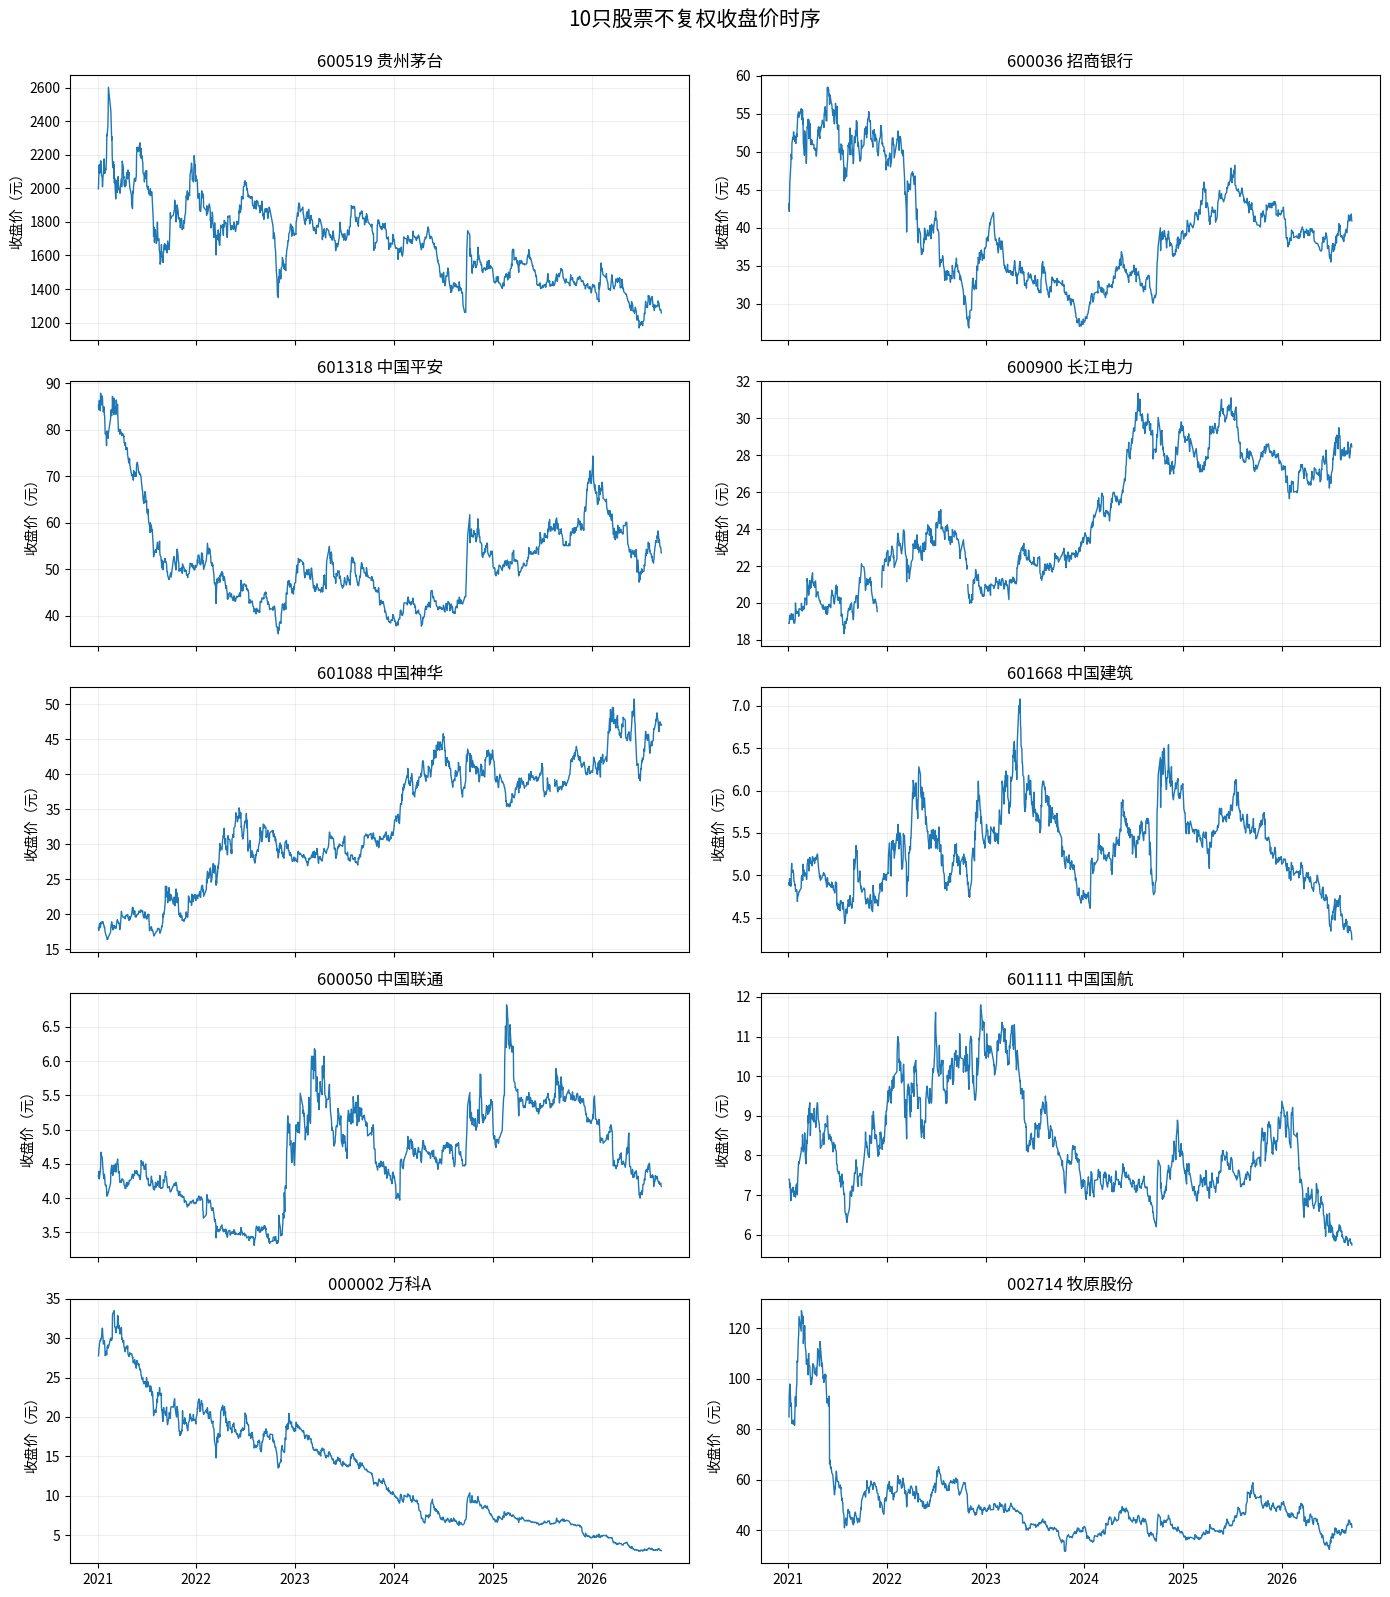

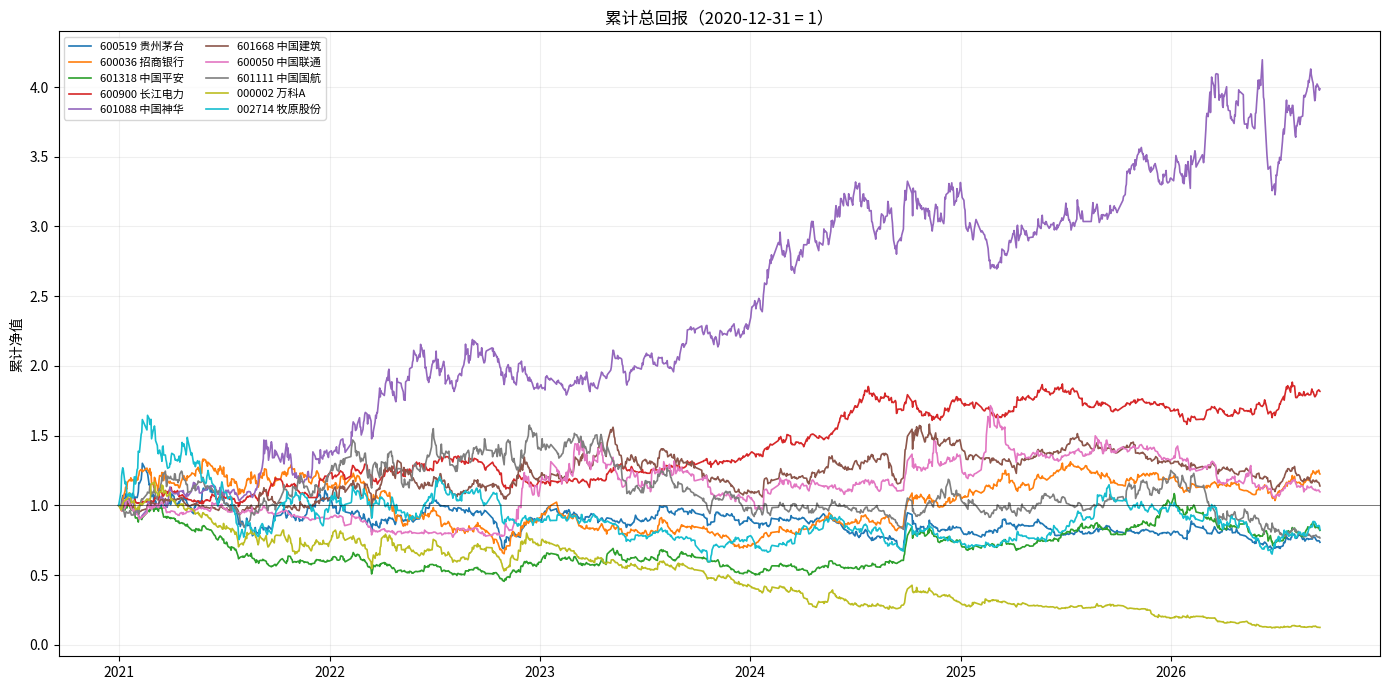

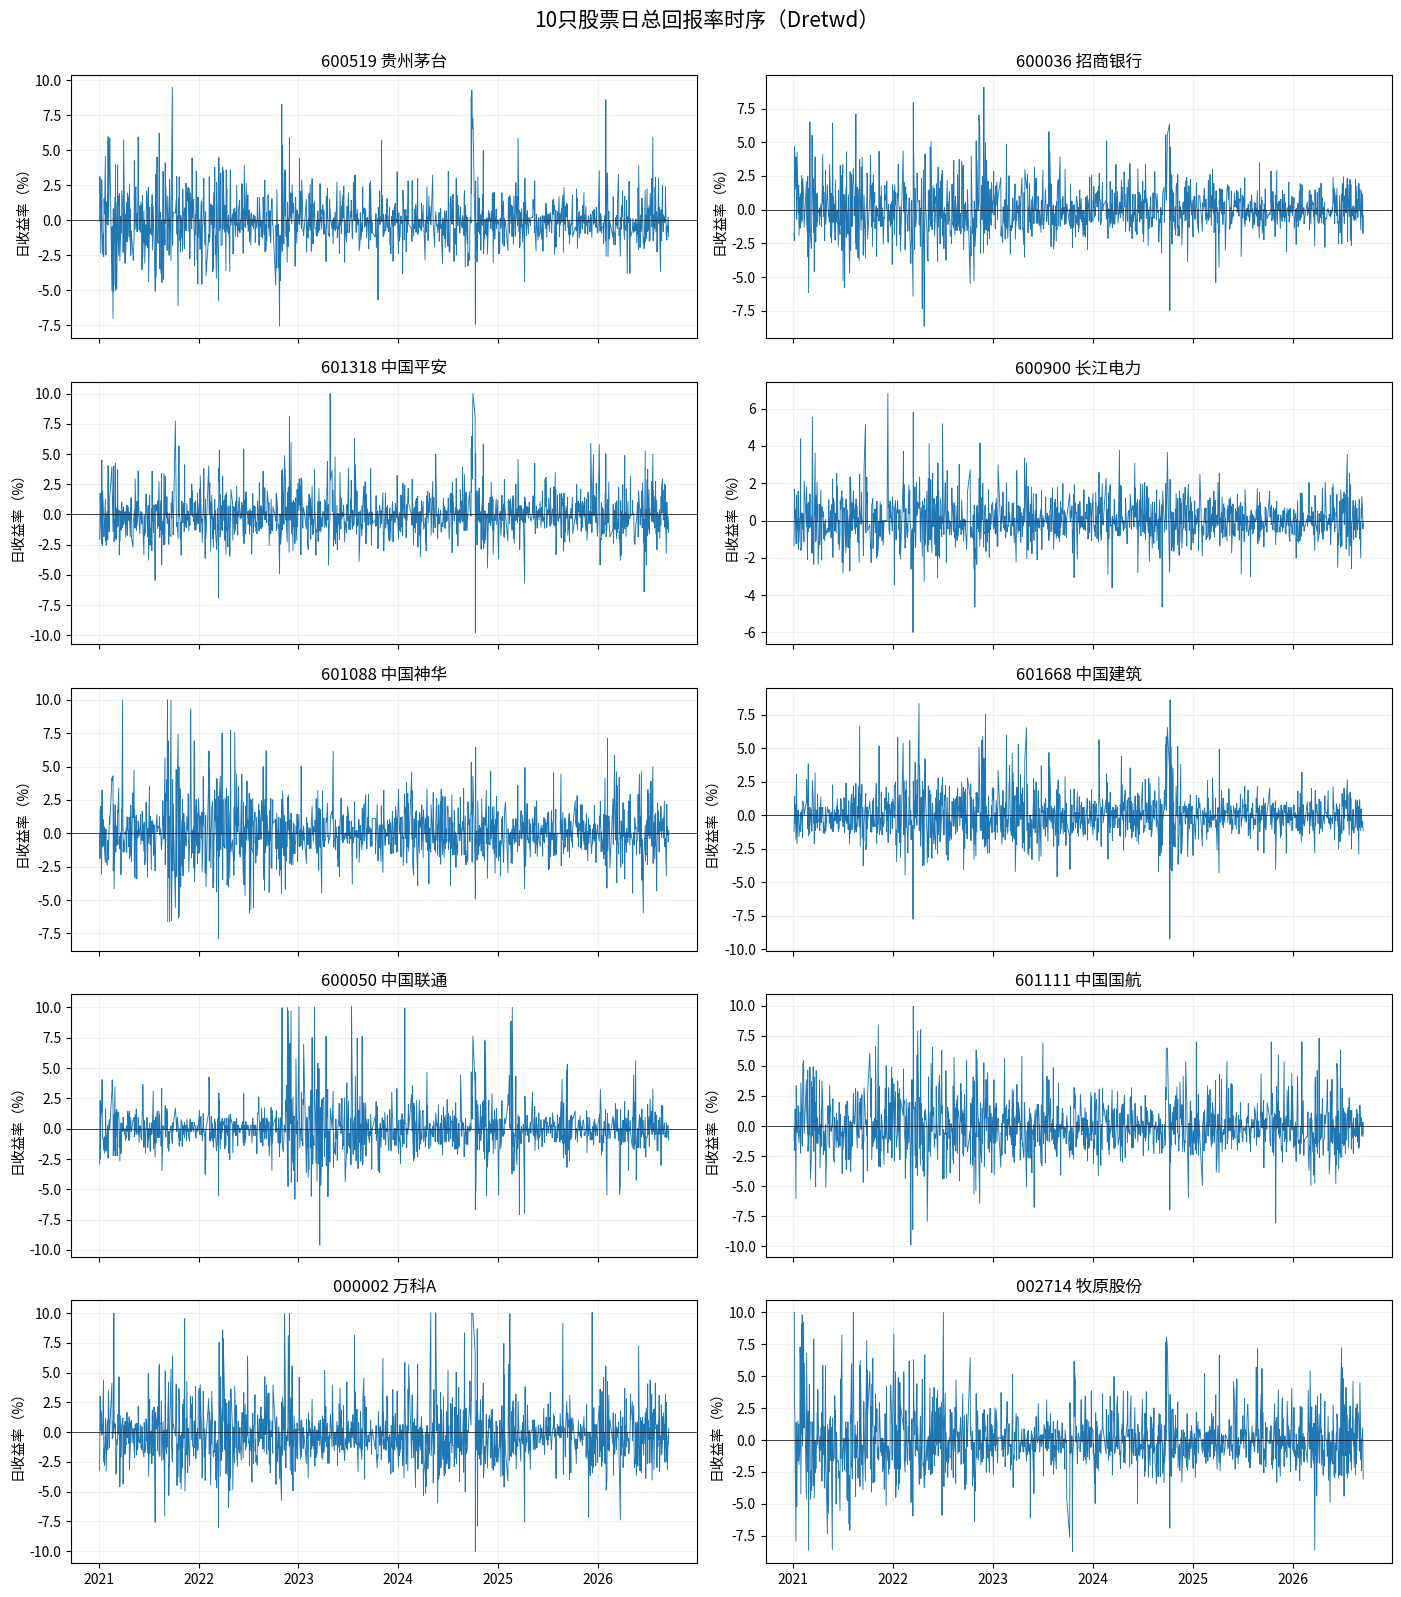

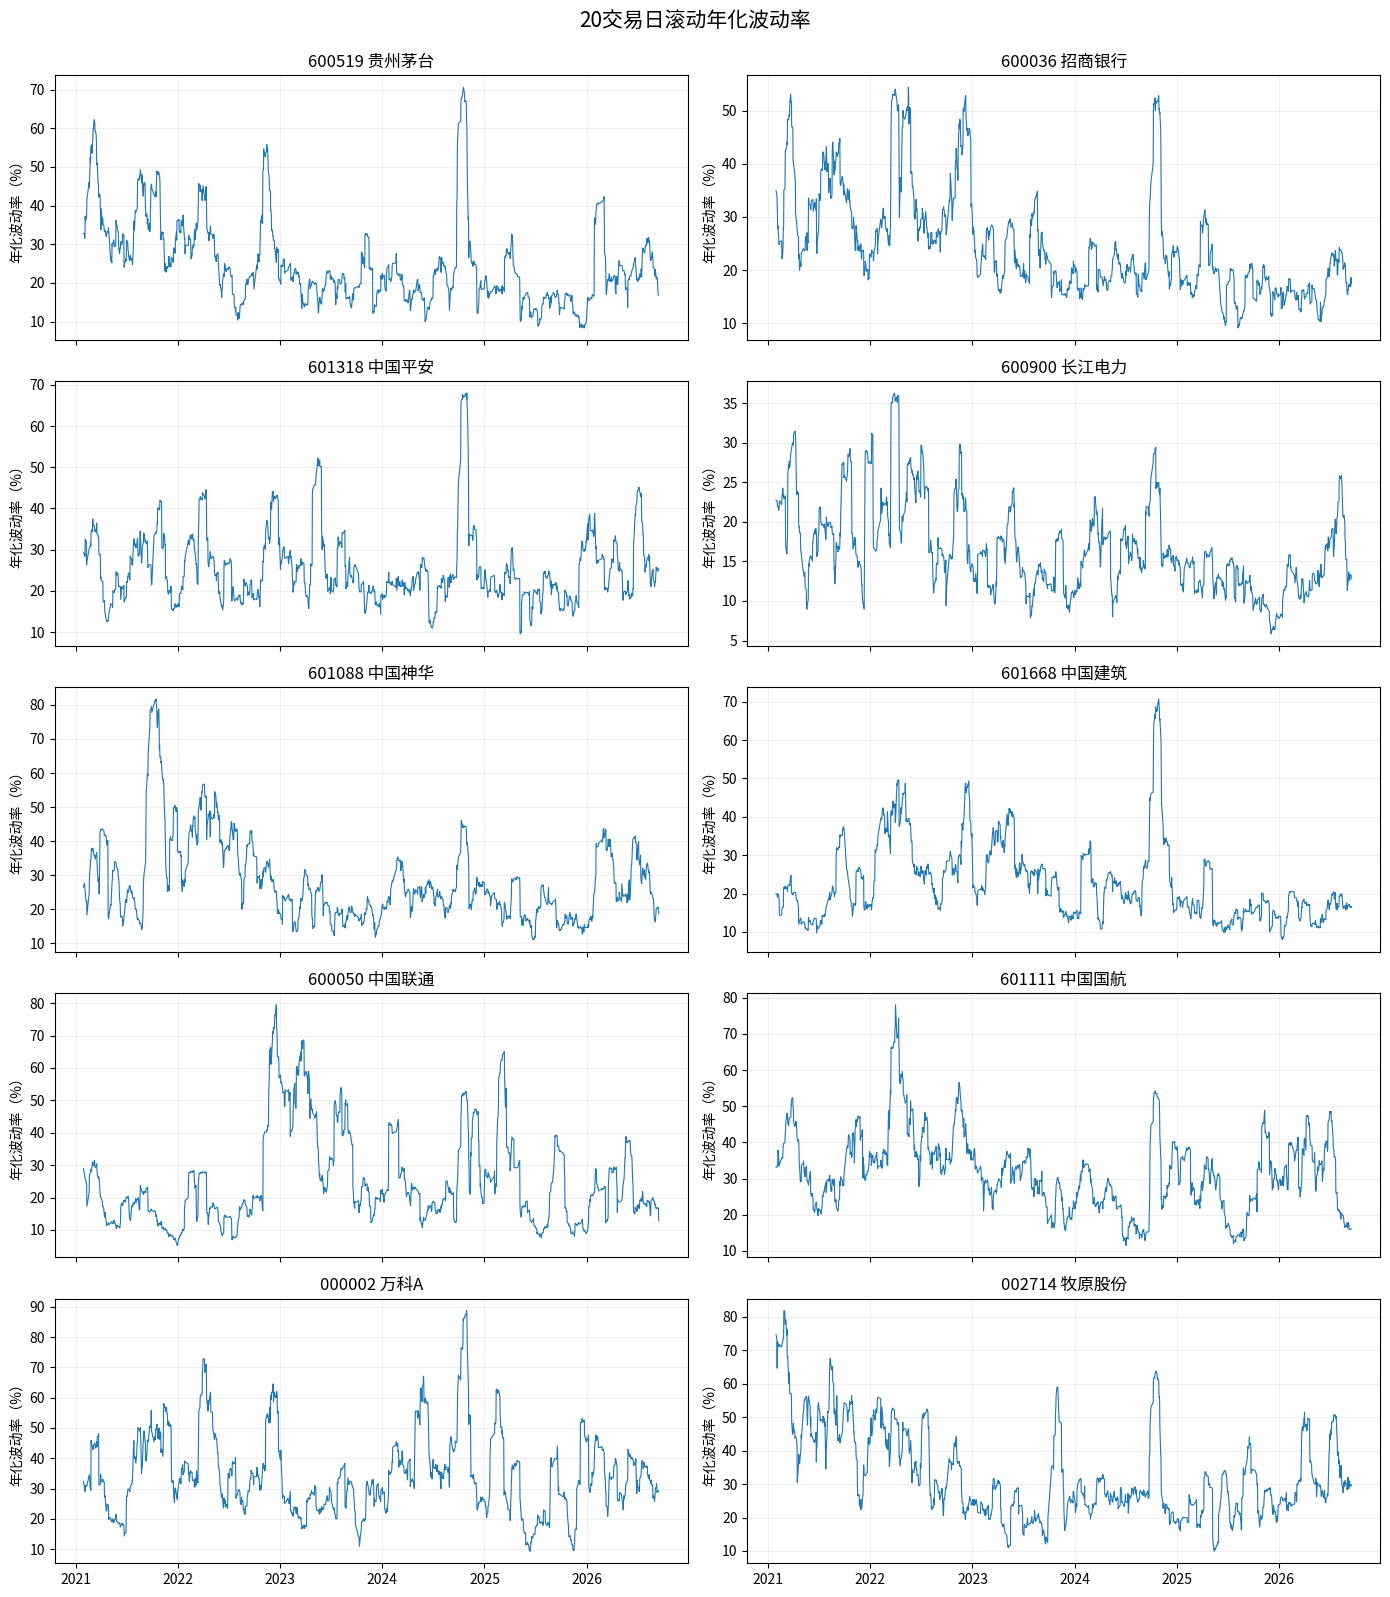

,name,N,mean,sd,min,median,max,skew,excess_kurtosis
600519,贵州茅台,1384.0,-0.0001,0.0172,-0.0756,-0.0010,0.0950,0.5844,4.3332
600036,招商银行,1384.0,0.0003,0.0169,-0.0864,-0.0007,0.0907,0.2994,3.3011
601318,中国平安,1384.0,0.0000,0.0171,-0.0977,-0.0011,0.1000,0.7310,4.2820
600900,长江电力,1384.0,0.0005,0.0110,-0.0600,0.0000,0.0681,0.4905,4.1074
601088,中国神华,1384.0,0.0012,0.0191,-0.0790,0.0004,0.1000,0.5136,3.3366
601668,中国建筑,1384.0,0.0002,0.0156,-0.0923,0.0000,0.0862,0.6506,4.4435
600050,中国联通,1384.0,0.0002,0.0184,-0.0959,0.0000,0.1011,1.2857,8.0447
601111,中国国航,1384.0,0.0000,0.0209,-0.0990,-0.0013,0.0998,0.3921,2.2441
000002,万科A,1384.0,-0.0012,0.0235,-0.1002,-0.0028,0.1006,0.8529,3.3984
002714,牧原股份,1384.0,0.0001,0.0227,-0.0872,-0.0013,0.1000,0.6096,3.0731


In [4]:
name_map = dict(zip(selection["代码"], selection["简称"]))

# 图1：不复权收盘价，保留原始缺口，不对画图数据填补
fig, axes = plt.subplots(5,2,figsize=(14,16),sharex=True)
for ax,c in zip(axes.ravel(), codes):
    ax.plot(close_observed.index, close_observed[c], linewidth=1)
    ax.set_title(f"{c} {name_map[c]}")
    ax.set_ylabel("收盘价（元）")
    ax.grid(alpha=.2)
fig.suptitle("10只股票不复权收盘价时序", y=.995, fontsize=15)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig01-close-price.png",dpi=160,bbox_inches="tight"); plt.show()

# 图2：累计总回报，基准日设为1
cum = (1+ret).cumprod()
baseline = pd.DataFrame([np.ones(len(codes))], index=[pd.Timestamp("2020-12-31")], columns=codes)
cum_plot = pd.concat([baseline,cum])
fig, ax = plt.subplots(figsize=(14,7))
for c in codes: ax.plot(cum_plot.index,cum_plot[c],label=f"{c} {name_map[c]}",linewidth=1.2)
ax.axhline(1,color="black",linewidth=.7,alpha=.5); ax.set_title("累计总回报（2020-12-31 = 1）"); ax.set_ylabel("累计净值"); ax.legend(ncol=2,fontsize=8); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig02-cumulative-performance.png",dpi=160,bbox_inches="tight"); plt.show()

# 图3：日收益率
fig, axes = plt.subplots(5,2,figsize=(14,16),sharex=True)
for ax,c in zip(axes.ravel(), codes):
    ax.plot(ret.index,ret[c]*100,linewidth=.65)
    ax.axhline(0,color="black",linewidth=.5); ax.set_title(f"{c} {name_map[c]}"); ax.set_ylabel("日收益率（%）"); ax.grid(alpha=.2)
fig.suptitle("10只股票日总回报率时序（Dretwd）", y=.995, fontsize=15)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig03-daily-return.png",dpi=160,bbox_inches="tight"); plt.show()

# 图4：20日滚动年化波动率
rollvol = ret.rolling(20,min_periods=20).std(ddof=1)*np.sqrt(252)
fig, axes = plt.subplots(5,2,figsize=(14,16),sharex=True)
for ax,c in zip(axes.ravel(), codes):
    ax.plot(rollvol.index,rollvol[c]*100,linewidth=.8)
    ax.set_title(f"{c} {name_map[c]}"); ax.set_ylabel("年化波动率（%）"); ax.grid(alpha=.2)
fig.suptitle("20交易日滚动年化波动率", y=.995, fontsize=15)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig04-rolling-volatility.png",dpi=160,bbox_inches="tight"); plt.show()

# 描述统计
stats = pd.DataFrame(index=codes)
for c in codes:
    r=ret[c].dropna()
    stats.loc[c,"N"] = len(r); stats.loc[c,"mean"] = r.mean(); stats.loc[c,"sd"] = r.std(ddof=1)
    stats.loc[c,"min"] = r.min(); stats.loc[c,"median"] = r.median(); stats.loc[c,"max"] = r.max()
    stats.loc[c,"skew"] = r.skew(); stats.loc[c,"excess_kurtosis"] = r.kurt()
stats.insert(0,"name",[name_map[c] for c in stats.index])
display(stats.round(4))
stats.to_csv(OUT_TAB/"hw02-1-descriptive-statistics.csv",encoding="utf-8-sig")

**结果解读。** 样本期个股分化显著：中国神华累计净值约 **3.99**、长江电力约 **1.82**，而万科 A 约 **0.13**。这反映的是本次固定样本在 2021—2026 年间的事后表现，不应外推为未来收益预测。

风险方面，万科 A 与牧原股份的日收益标准差最高（约 **2.35%** 与 **2.27%**），长江电力最低（约 **1.10%**）。多只股票的超额峰度明显大于 0，说明日收益具有厚尾；中国联通偏度与峰度尤其高。极端日收益多数接近 ±10%，与主板股票价格限制附近的波动一致，未发现明显单位或小数点错误。滚动波动率还显示风险具有显著的时间聚集，而不是恒定不变。

## 5. Pearson 相关性

相关性按上一步对齐后的 1,384 个共同交易日计算。由于内部停牌式缺口已按明确规则记为 0，其余缺失不存在，因此每一对股票使用相同日历；这避免了不同股票对使用不同日期集合造成的不可比性。

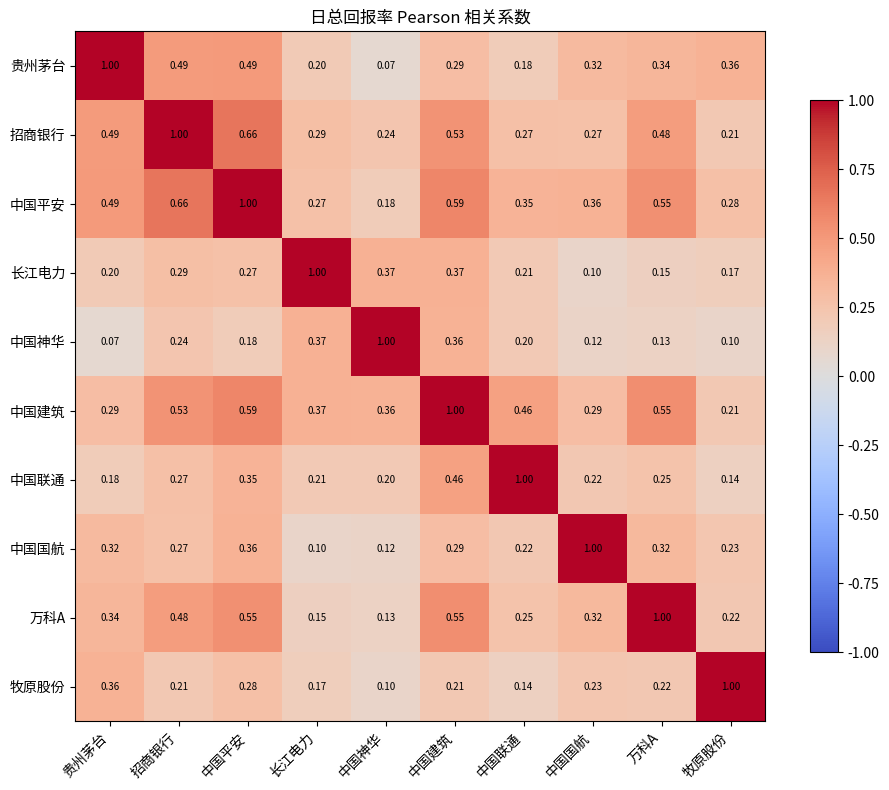

,corr,code1,code2
0,0.658,600036,601318
1,0.589,601318,601668
2,0.551,601668,000002
3,0.546,601318,000002
4,0.529,600036,601668
5,0.493,600519,601318
6,0.488,600519,600036
7,0.479,600036,000002


In [5]:
corr = ret.corr(method="pearson")
fig, ax = plt.subplots(figsize=(10,8))
im=ax.imshow(corr.values,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(codes)),[name_map[c] for c in codes],rotation=45,ha="right")
ax.set_yticks(range(len(codes)),[name_map[c] for c in codes])
for i in range(len(codes)):
    for j in range(len(codes)):
        ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center",fontsize=7)
ax.set_title("日总回报率 Pearson 相关系数")
fig.colorbar(im,ax=ax,shrink=.8); fig.tight_layout(); fig.savefig(OUT_FIG/"fig05-correlation-heatmap.png",dpi=160,bbox_inches="tight"); plt.show()

pairs=[]
for i,a in enumerate(codes):
    for b in codes[i+1:]: pairs.append((corr.loc[a,b],a,b))
pair_table=pd.DataFrame(sorted(pairs,reverse=True),columns=["corr","code1","code2"])
display(pair_table.head(8).round(3))

**相关性解读。** 最高的相关系数出现在招商银行与中国平安，约 **0.66**；中国平安与中国建筑、万科 A，以及招商银行与中国建筑也表现出较高的共同波动。相反，中国神华与贵州茅台的相关系数只有约 **0.07**。同属金融或对宏观信用条件更敏感的股票相关性较高，而能源、消费、公用事业之间的相关性较低，说明跨行业组合确实提供了分散化空间。不过相关系数仍是样本期线性共同波动的描述，不代表稳定的结构关系。

## 6. 等权组合与上一交易日总市值加权组合

组合采用每日目标权重、忽略交易成本。等权组合每天 10%/股；市值组合的 $t$ 日权重只使用 $t-1$ 日 `Dsmvtll`，严格避免前视偏差。`Dsmvtll` 是**总市值**而非流通市值。

$$
r^{EW}_{p,t}=\sum_i 0.1r_{i,t},\qquad
w_{i,t-1}=\frac{MV_{i,t-1}}{\sum_j MV_{j,t-1}},\qquad
r^{VW}_{p,t}=\sum_i w_{i,t-1}r_{i,t}.
$$

,value
min_weight_sum,1.0
max_weight_sum,1.0
missing_lagged_mcap,0
first_evaluation_date,2021-01-04


,T,end_NAV,ann_return,ann_vol,max_drawdown,avg_HHI
Equal Weight,1384.0,1.0928,0.0163,0.1754,0.2267,0.1000
Value Weight,1384.0,1.0303,0.0054,0.1863,0.3568,0.2107


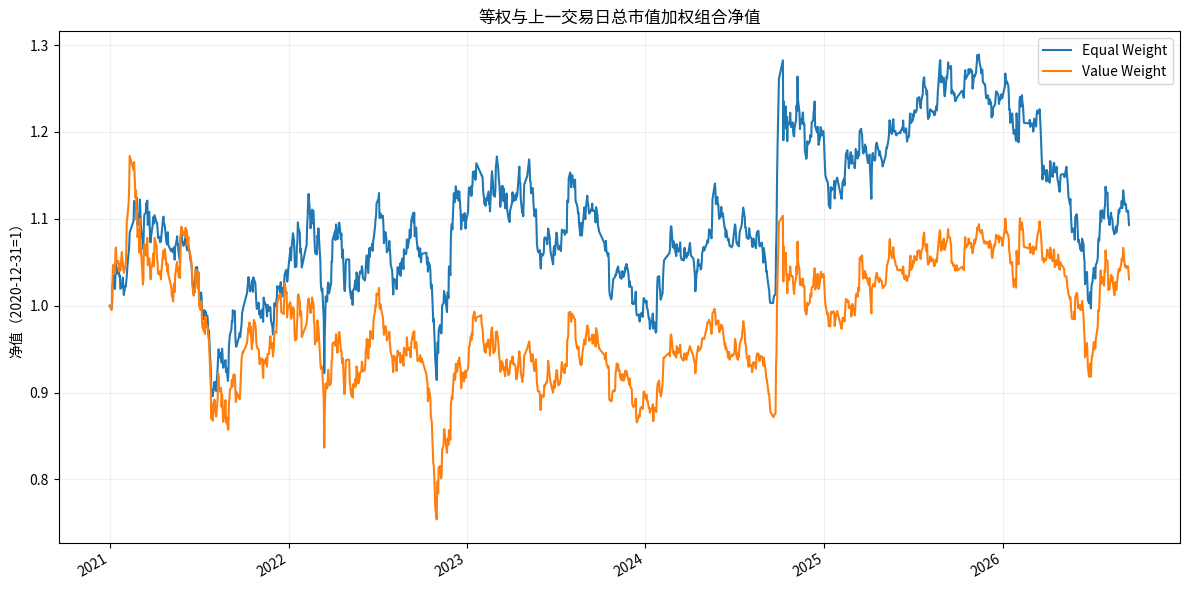

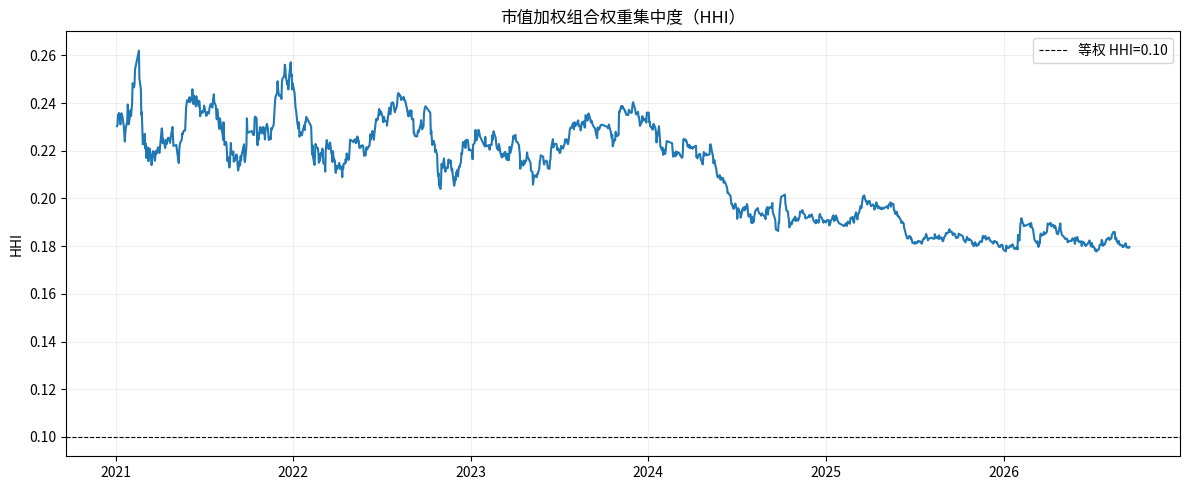

,name,2021-01-04 weight,2026-09-16 weight
code,,,
600519,贵州茅台,0.4127,0.3041
601318,中国平安,0.1549,0.1098
600036,招商银行,0.1491,0.1620
600900,长江电力,0.0717,0.1333
601088,中国神华,0.0488,0.1644
002714,牧原股份,0.0475,0.0442
000002,万科A,0.0459,0.0056
601668,中国建筑,0.0343,0.0339
600050,中国联通,0.0227,0.0250


In [6]:
# 使用包含2020年12月的完整日历，先得到上一交易日总市值
mv_full = panel["Dsmvtll"].unstack("code").reindex(columns=codes)
lag_mv = mv_full.shift(1).loc[ret.index]
weights_vw = lag_mv.div(lag_mv.sum(axis=1),axis=0)

# QA：权重必须加总为1，且正式样本第一日可使用2020-12-31总市值
weight_qa = pd.Series({
    "min_weight_sum":weights_vw.sum(axis=1).min(),
    "max_weight_sum":weights_vw.sum(axis=1).max(),
    "missing_lagged_mcap":int(lag_mv.isna().sum().sum()),
    "first_evaluation_date":str(ret.index.min().date()),
})
display(weight_qa.to_frame("value"))

r_ew = ret.mean(axis=1)
r_vw = (weights_vw*ret).sum(axis=1)
portfolio = pd.DataFrame({"Equal Weight":r_ew,"Value Weight":r_vw})

def perf(r):
    nav=(1+r).cumprod(); T=len(r)
    ann=nav.iloc[-1]**(252/T)-1
    vol=r.std(ddof=1)*np.sqrt(252)
    drawdown=nav/nav.cummax()-1
    return pd.Series({"T":T,"end_NAV":nav.iloc[-1],"ann_return":ann,"ann_vol":vol,"max_drawdown":-drawdown.min()})

perf_table = pd.DataFrame({c:perf(portfolio[c]) for c in portfolio}).T
perf_table["avg_HHI"] = [0.1, (weights_vw**2).sum(axis=1).mean()]
display(perf_table.round(4))
perf_table.to_csv(OUT_TAB/"hw02-1-portfolio-performance.csv",encoding="utf-8-sig")

nav=(1+portfolio).cumprod()
nav_plot=pd.concat([pd.DataFrame([[1,1]],index=[pd.Timestamp("2020-12-31")],columns=nav.columns),nav])
fig,ax=plt.subplots(figsize=(12,6))
nav_plot.plot(ax=ax,linewidth=1.5); ax.set_title("等权与上一交易日总市值加权组合净值"); ax.set_ylabel("净值（2020-12-31=1）"); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig06-portfolio-nav.png",dpi=160,bbox_inches="tight"); plt.show()

# 展示市值组合集中度及首尾权重
hhi=(weights_vw**2).sum(axis=1)
fig,ax=plt.subplots(figsize=(12,5)); ax.plot(hhi.index,hhi); ax.axhline(.1,color="black",linestyle="--",linewidth=.8,label="等权 HHI=0.10")
ax.set_title("市值加权组合权重集中度（HHI）"); ax.set_ylabel("HHI"); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig07-weight-concentration.png",dpi=160,bbox_inches="tight"); plt.show()

start_end = pd.DataFrame({"2021-01-04 weight":weights_vw.iloc[0],"2026-09-16 weight":weights_vw.iloc[-1]})
start_end.insert(0,"name",[name_map[c] for c in start_end.index])
display(start_end.sort_values("2021-01-04 weight",ascending=False).round(4))

**组合比较。** 两个组合使用完全相同的 **1,384** 个交易日。等权组合期末净值约 **1.093**，几何年化收益约 **1.63%**，年化波动率约 **17.54%**，最大回撤约 **22.67%**；市值组合期末净值约 **1.030**，年化收益约 **0.54%**，年化波动率约 **18.63%**，最大回撤约 **35.68%**。在这一特定样本中，等权组合不仅收益更高，而且风险指标更低。

差异的重要来源是权重集中。市值组合平均 HHI 约 **0.211**，明显高于等权组合的 0.10。2021-01-04 市值权重中贵州茅台约占 **41%**，招商银行和中国平安也占较大比重；到 2026-09-16，贵州茅台仍约占 **30%**。因此“10 只股票”并不自动等于充分分散，市值权重会让大市值股票主导组合表现。上述结论是样本内结果，不包含交易成本，也不代表可预测的未来优劣。

## 7. 总体结论

本题基于 CSMAR 的真实日度数据构建了 10 只跨行业 A 股的统一总回报序列。原始 `code-date` 主键唯一，收益与总市值字段完整；仅识别出 21 个位于股票自身观测区间内、同时市场正常开市的停牌式缺口，并在明确说明后将这些持有日收益记为 0，而没有对所有缺失值机械填零。`Dretwd` 与不考虑现金红利的 `Dretnd` 在多个除息日存在差异，因此使用前者更符合“考虑分红等公司行为后收益”的作业口径。

个股层面，样本期收益与风险差异很大，收益分布普遍具有厚尾，且行业间相关性并不一致。组合层面，上一交易日总市值加权组合的权重高度集中于少数大市值公司；在 2021-01-04 至 2026-09-16 的样本内，等权组合取得更高的期末净值与年化收益，同时波动率和最大回撤更低。该结果说明分散化效果不仅取决于持股数量，也取决于权重集中程度。局限包括：只分析事先固定的 10 只股票、忽略交易成本与税费，并且停牌缺口是根据交易日横截面诊断而非额外交易状态字段识别，因此不应把本结果视为未来投资策略预测。